# Experiment 7: Heatmaps and Tree Maps

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle

            Unit_Price  Quantity  Discount     Sales    Profit
Unit_Price    1.000000 -0.877533  0.645806  0.398433 -0.477352
Quantity     -0.877533  1.000000 -0.764265 -0.388629  0.536277
Discount      0.645806 -0.764265  1.000000 -0.104287 -0.920968
Sales         0.398433 -0.388629 -0.104287  1.000000  0.428853
Profit       -0.477352  0.536277 -0.920968  0.428853  1.000000


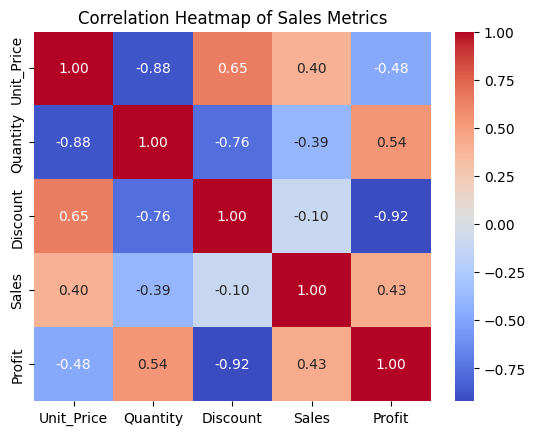

In [2]:
df_metrics = pd.DataFrame({
    'Unit_Price': [100, 250, 400, 150, 600, 320, 80, 500, 220, 750],
    'Quantity': [10, 5, 3, 8, 2, 4, 12, 3, 6, 2],
    'Discount': [0.05, 0.10, 0.20, 0.00, 0.15, 0.10, 0.00, 0.25, 0.05, 0.10],
    'Sales': [950, 1125, 960, 1200, 1020, 1152, 960, 1125, 1254, 1350],
    'Profit': [250, 280, 110, 340, 190, 260, 290, 120, 310, 270]
})
corr = df_metrics.corr()
print(corr)
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Sales Metrics')
plt.show()

In [3]:
df_cat = pd.DataFrame({
    'Category': ['Technology', 'Technology', 'Technology', 'Furniture', 'Furniture', 'Office Supplies', 'Office Supplies'],
    'Sub_Category': ['Laptops', 'Phones', 'Accessories', 'Chairs', 'Tables', 'Binders', 'Paper'],
    'Sales': [55000, 42000, 18000, 31000, 24000, 15000, 12000]
})
print(df_cat)

          Category Sub_Category  Sales
0       Technology      Laptops  55000
1       Technology       Phones  42000
2       Technology  Accessories  18000
3        Furniture       Chairs  31000
4        Furniture       Tables  24000
5  Office Supplies      Binders  15000
6  Office Supplies        Paper  12000


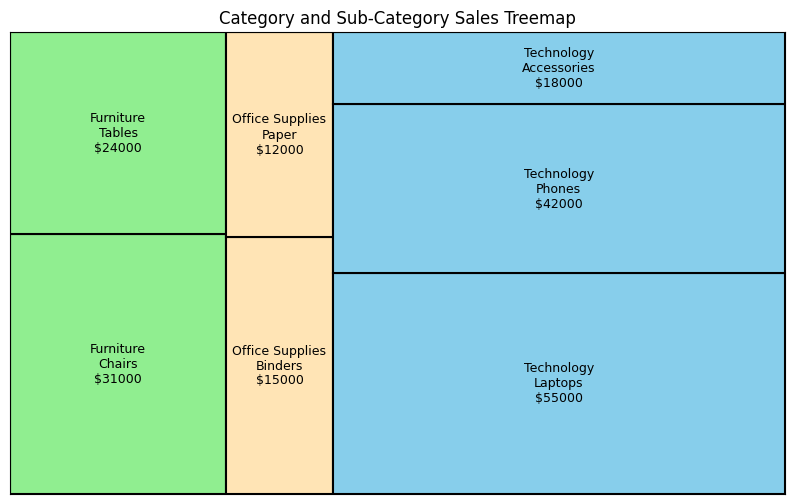

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
total_sales = df_cat['Sales'].sum()
cat_totals = df_cat.groupby('Category')['Sales'].sum()
cat_colors = {'Technology': 'skyblue', 'Furniture': 'lightgreen', 'Office Supplies': 'moccasin'}

x = 0.0
for cat, cat_sum in cat_totals.items():
    w = cat_sum / total_sales
    sub_df = df_cat[df_cat['Category'] == cat]
    y = 0.0
    for _, row in sub_df.iterrows():
        h = row['Sales'] / cat_sum
        rect = Rectangle((x, y), w, h, facecolor=cat_colors[cat], edgecolor='black', linewidth=1.5)
        ax.add_patch(rect)
        ax.text(x + w / 2, y + h / 2, cat + "\n" + row['Sub_Category'] + "\n$" + str(row['Sales']), ha='center', va='center', fontsize=9)
        y += h
    x += w

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xticks([])
ax.set_yticks([])
plt.title('Category and Sub-Category Sales Treemap')
plt.show()